# Diffusion in 2D/3D

Course assignment. The goal is to simulate a particle diffusing on a 2D/3D lattice, look at the distribution of end-to-end distances for a fixed number of steps, and understand how MSD depends on N.

## Background

Diffusion can be modelled as a random walk: at every time step the particle moves one lattice unit in a randomly chosen direction. A single walk is unpredictable, so to describe diffusion I look at many walks together and at their **mean square displacement (MSD)**, the average of the squared distance from the starting point.

For a random walk the theory says `MSD = 2·d·D·t`, where d is the number of dimensions, D is the diffusion constant and t is the time (here, the number of steps). So in 2D `MSD = 4Dt` and in 3D `MSD = 6Dt`.

I use numpy for the arrays and the random numbers and matplotlib for the plots. The random seed is fixed so that running the notebook again gives the same numbers as the ones I quote in the text.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# fixed seed so that the numbers quoted in the text can be reproduced
np.random.seed(1)

## 1) Function to simulate the 2D walk

I wrote a function that takes N steps, picks a random direction at each step (0=up, 1=down, 2=right, 3=left) and stores all the coordinates.

How it works:

- `pos` is an array with one row per step and two columns (x and y). The first row stays at zero, so the walk starts at [0,0].
- `steps` contains all the random directions, drawn in one call with `np.random.randint(0, 4, N)`.
- In the loop, each new position is a copy of the previous one with one coordinate changed by +1 or -1.

The array holds N positions including the starting point, so the particle actually makes N-1 moves. For the values of N I use this makes no visible difference.

In [2]:
def diffuse2d(N):
    pos = np.zeros((N, 2))
    steps = np.random.randint(0, 4, N)

    for i in range(1, N):
        pos[i] = pos[i-1]
        if   steps[i] == 0: pos[i, 1] += 1   # up
        elif steps[i] == 1: pos[i, 1] -= 1   # down
        elif steps[i] == 2: pos[i, 0] += 1   # right
        else:               pos[i, 0] -= 1   # left

    return pos

Testing it with 1000 steps and plotting the path. The green dot is the starting point and the red dot is the final position.

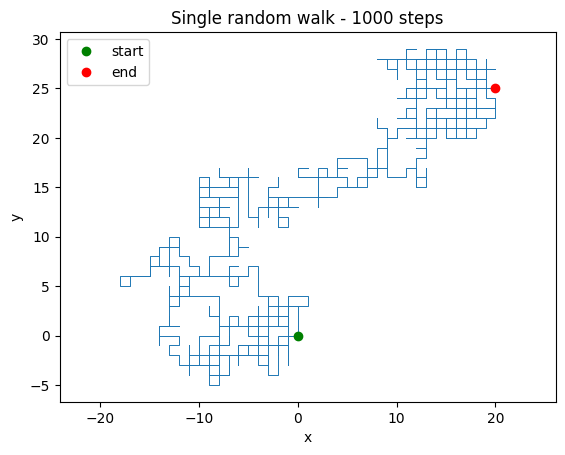

In [3]:
path = diffuse2d(1000)

plt.figure()
plt.plot(path[:, 0], path[:, 1], lw=0.7)
plt.plot(0, 0, 'go', label='start')
plt.plot(path[-1, 0], path[-1, 1], 'ro', label='end')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Single random walk - 1000 steps')
plt.legend()
plt.axis('equal')
plt.show()

The particle wanders around randomly and crosses its own path many times. It doesn't go that far from the origin even after 1000 steps: the end point is only about 32 lattice units away from the start, because steps in opposite directions cancel each other.

## 2) Many particles - displacement distribution and MSD

Now I run 1000 particles, each for 1000 steps, and collect where each one ends up. For every particle I keep only the final position (the last row of the path). I plot it as a red dot and store the squared displacement r² = x² + y² in a list. The MSD is the mean of that list.

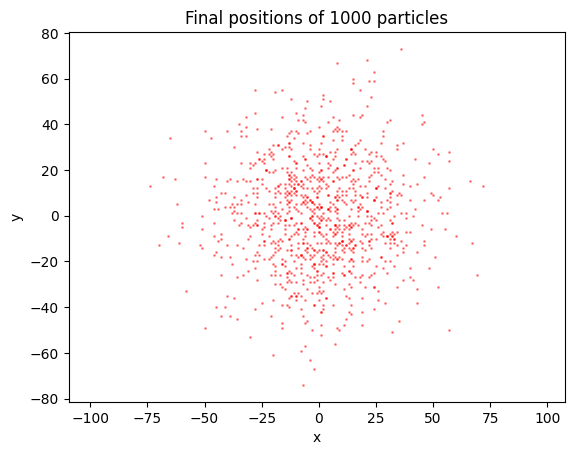

MSD = 1041.596


In [4]:
M = 1000
N = 1000
displacements = []

plt.figure()
for _ in range(M):
    path = diffuse2d(N)
    xf, yf = path[-1]
    plt.plot(xf, yf, 'r.', ms=2, alpha=0.4)
    displacements.append(xf**2 + yf**2)

plt.xlabel('x')
plt.ylabel('y')
plt.title('Final positions of 1000 particles')
plt.axis('equal')
plt.show()

print('MSD =', np.mean(displacements))

The final positions form a round cloud centred on the origin, so there is no preferred direction, and most particles end up within a few tens of lattice units from the start.

Next I look at how the displacements are distributed, with one histogram for the squared displacement r² and one for the distance r itself.

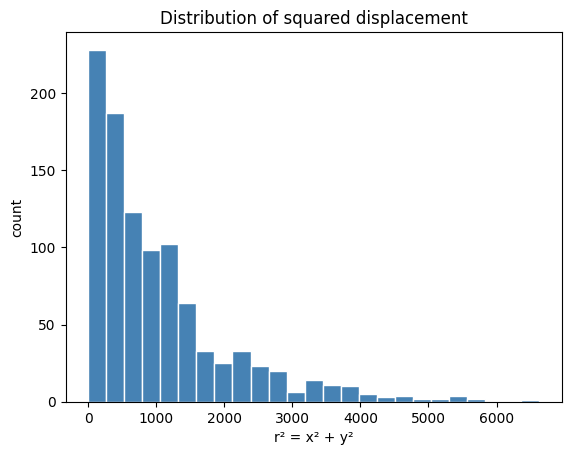

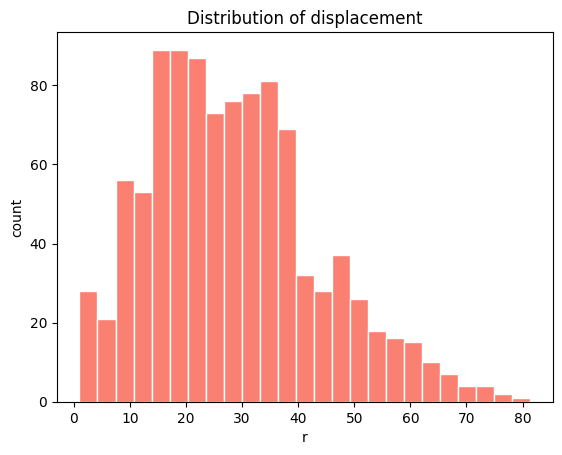

In [5]:
# histogram of r^2
plt.figure()
plt.hist(displacements, bins=25, color='steelblue', edgecolor='white')
plt.xlabel('r² = x² + y²')
plt.ylabel('count')
plt.title('Distribution of squared displacement')
plt.show()

# histogram of r
plt.figure()
plt.hist(np.sqrt(displacements), bins=25, color='salmon', edgecolor='white')
plt.xlabel('r')
plt.ylabel('count')
plt.title('Distribution of displacement')
plt.show()

The squared displacement has an exponential-like shape, meaning most particles don't go very far. The actual distance r looks more bell-shaped, but it is not symmetric: it starts at zero and has a longer tail on the right. The MSD comes out at about 1040, close to the number of steps (1000) — I'll check that properly in the next part.

## 3) MSD vs number of steps

I repeat the simulation for different values of N and see how MSD scales. I expect it to be linear because in 2D the theory says `MSD = 4Dt`, so MSD should just grow proportionally with N.

For each N in the list I simulate 1000 walks and take the mean of r². Then `np.polyfit(Nsteps, msd, 1)` fits a straight line through the five points; the first value it returns is the slope. Since `MSD = 4Dt`, the diffusion constant is the slope divided by 4.

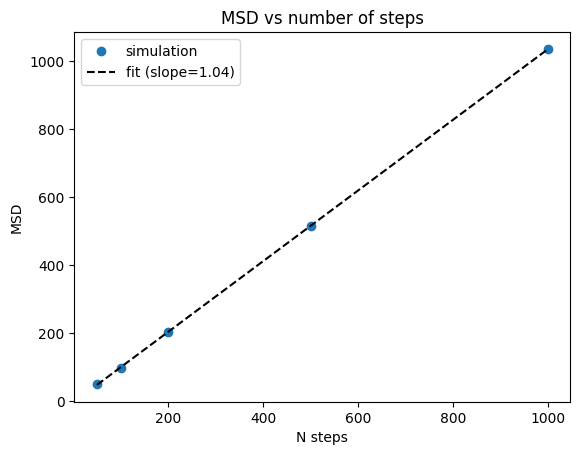

slope: 1.038
diffusion constant D = slope/4 = 0.26


In [6]:
Nsteps = [50, 100, 200, 500, 1000]
msd = []

for N in Nsteps:
    r2 = []
    for _ in range(1000):
        path = diffuse2d(N)
        xf, yf = path[-1]
        r2.append(xf**2 + yf**2)
    msd.append(np.mean(r2))

# fit a line through the points
fit = np.polyfit(Nsteps, msd, 1)

plt.figure()
plt.plot(Nsteps, msd, 'o', label='simulation')
plt.plot(Nsteps, np.polyval(fit, Nsteps), 'k--', label=f'fit (slope={fit[0]:.2f})')
plt.xlabel('N steps')
plt.ylabel('MSD')
plt.title('MSD vs number of steps')
plt.legend()
plt.show()

print('slope:', round(fit[0], 3))
print('diffusion constant D = slope/4 =', round(fit[0]/4, 3))

MSD grows linearly with N as expected, and the slope is close to 1 (1.04), giving D ≈ 0.26, close to the expected 0.25. The slope should be 1 because each step is 1 unit long and the steps are independent, so every step adds 1 to the MSD on average. With 1000 walks the statistical error of each MSD value is about 3%, so a slope of 1.04 is consistent with 1.

The linear relationship means that the typical distance from the start grows like √N, not like N — this is what makes diffusion slow compared to just moving in a straight line. To go twice as far, the particle needs four times as many steps.

## 4) Same thing in 3D

I just extend the function to 3D by adding ±z directions (so 6 possible moves instead of 4). The array now has three columns (x, y, z) and the random number goes from 0 to 5. The theory now gives `MSD = 6Dt`.

In [7]:
def diffuse3d(N):
    pos = np.zeros((N, 3))
    steps = np.random.randint(0, 6, N)

    for i in range(1, N):
        pos[i] = pos[i-1]
        if   steps[i] == 0: pos[i, 0] += 1
        elif steps[i] == 1: pos[i, 0] -= 1
        elif steps[i] == 2: pos[i, 1] += 1
        elif steps[i] == 3: pos[i, 1] -= 1
        elif steps[i] == 4: pos[i, 2] += 1
        else:               pos[i, 2] -= 1

    return pos

Then I repeat the analysis of part 3 with the 3D function: 1000 walks for each N, the mean of r² = x² + y² + z², and a straight-line fit. I plot the 2D and the 3D results together to compare them. In 3D the diffusion constant is the slope divided by 6.

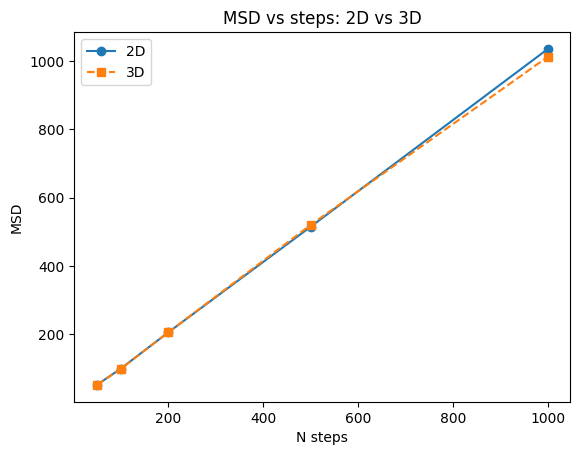

3D slope: 1.016
3D diffusion constant D = slope/6 = 0.169


In [8]:
msd_3d = []

for N in Nsteps:
    r2 = []
    for _ in range(1000):
        path = diffuse3d(N)
        xf, yf, zf = path[-1]
        r2.append(xf**2 + yf**2 + zf**2)
    msd_3d.append(np.mean(r2))

fit_3d = np.polyfit(Nsteps, msd_3d, 1)

plt.figure()
plt.plot(Nsteps, msd,    'o-', label='2D')
plt.plot(Nsteps, msd_3d, 's--', label='3D')
plt.xlabel('N steps')
plt.ylabel('MSD')
plt.title('MSD vs steps: 2D vs 3D')
plt.legend()
plt.show()

print('3D slope:', round(fit_3d[0], 3))
print('3D diffusion constant D = slope/6 =', round(fit_3d[0]/6, 3))

The MSD is still linear with N in 3D and the slope is again about 1 (1.02), because each step still has length 1 whatever the dimension. What changes is D = slope/6 ≈ 0.17 instead of 0.25 in 2D. The total MSD is the same, but it is now shared between three directions instead of two, so the spread along each single axis is smaller.

## Summary

- A random walk on a lattice reproduces the main property of diffusion: the mean square displacement grows linearly with the number of steps.
- The slope is about 1 in both 2D and 3D (1.04 and 1.02), which gives D ≈ 1/4 in 2D and D ≈ 1/6 in 3D in lattice units.
- The distance from the start grows only like the square root of the number of steps.
- The squared displacement of many particles has an exponential-like distribution, and the final positions form a cloud with no preferred direction.

Limits: each MSD value is an average over 1000 walks, so it has a statistical error of a few percent, and the line is fitted through only five values of N.